# Imports inciais e leitura do arquivo

In [87]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from plotly import graph_objects as go
import numpy as np
from scipy import stats as st
import re

In [88]:
df_logs = pd.read_csv('data/logs_exp_us.csv', sep='\t')
print(df_logs.head())
print()
df_logs.info()

                 EventName         DeviceIDHash  EventTimestamp  ExpId
0         MainScreenAppear  4575588528974610257      1564029816    246
1         MainScreenAppear  7416695313311560658      1564053102    246
2  PaymentScreenSuccessful  3518123091307005509      1564054127    248
3         CartScreenAppear  3518123091307005509      1564054127    248
4  PaymentScreenSuccessful  6217807653094995999      1564055322    248

<class 'pandas.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   EventName       244126 non-null  str  
 1   DeviceIDHash    244126 non-null  int64
 2   EventTimestamp  244126 non-null  int64
 3   ExpId           244126 non-null  int64
dtypes: int64(3), str(1)
memory usage: 7.5 MB


# Tratamento dos dados

In [89]:
print(f"Valores duplicados: {df_logs.duplicated().sum()}")
print(f"Proporção de valores duplicado: {((df_logs.duplicated().sum() / len(df_logs)) * 100).round(2)}%")


Valores duplicados: 413
Proporção de valores duplicado: 0.17%


Os duplicados representam apenas uma pequena parcela dos dados, 0,17%. Por esse fato, eles serão removidos.

In [90]:
df_logs = df_logs.drop_duplicates()

In [91]:
# Renomeação das colunas para snake_case
df_logs.columns = [re.sub(r'(?<!^)(?=[A-Z])', ' ', col) for col in df_logs.columns]
df_logs.columns = [col.replace(" ", "_").lower() for col in df_logs.columns]
df_logs = df_logs.rename(columns={'device_i_d_hash': 'device_id_hash'})

In [92]:
# Separação dos grupos para análises futuras
control_group = df_logs[(df_logs['exp_id'] == 246) | (df_logs['exp_id'] == 247)]
test_group = df_logs[df_logs['exp_id'] == 248]

In [93]:
# Separando uma coluna para data
df_logs['event_timestamp'] = pd.to_datetime(df_logs['event_timestamp'].astype('int64'), unit='s')
df_logs['date'] = df_logs['event_timestamp'].dt.date

In [94]:
print(df_logs.head(3))

                event_name       device_id_hash     event_timestamp  exp_id  \
0         MainScreenAppear  4575588528974610257 2019-07-25 04:43:36     246   
1         MainScreenAppear  7416695313311560658 2019-07-25 11:11:42     246   
2  PaymentScreenSuccessful  3518123091307005509 2019-07-25 11:28:47     248   

         date  
0  2019-07-25  
1  2019-07-25  
2  2019-07-25  


# Análise dos dados - Verificação

In [95]:
# Exibindo a quantidade de registros e usuários únicos
print(f"Total de {len(df_logs)} registros")
print(f"Total de {df_logs['device_id_hash'].nunique()} usuário unicos")

Total de 243713 registros
Total de 7551 usuário unicos


In [96]:
# Separando e exibindo a média de eventos por usuário
events_by_user = df_logs.groupby('device_id_hash').agg(event_count=('event_name', 'count')).reset_index()
print(f"O usuários tem em média {events_by_user['event_count'].mean().round(2)} eventos")

O usuários tem em média 32.28 eventos


Data mínima: 2019-07-25 
Data máxima: 2019-08-07


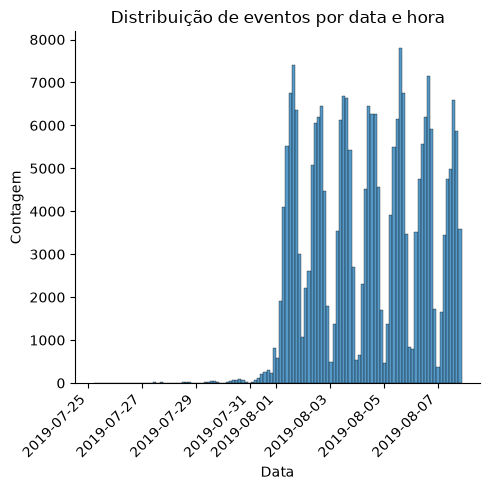

In [97]:
# Exibe a data mínima e máxima
print(f"Data mínima: {df_logs['date'].min()}",
      f"\nData máxima: {df_logs['date'].max()}")

# Gera uma gráfico que mostra a distribuição de eventos por data e hora
fig = sns.displot(data=df_logs,
             x=df_logs['event_timestamp'])
fig.set_xticklabels(rotation=45, ha='right')
plt.title('Distribuição de eventos por data e hora')
plt.ylabel('Contagem')
plt.xlabel('Data')
plt.tight_layout()
plt.show()

Não temos dados completos durante todo o período. A parte com menos registros vai de 2019-07-25 até 2019-07-31, cerca de 7 dias.\
Após isso, a contagem sobe para ~7500 eventos e segue em oscilação.

In [98]:
# Filtra os valores para deixar o dataframe mais limpo
df_logs_clean = df_logs[df_logs['event_timestamp'] >= '2019-08-01']

# Exibe a quantidade de registros excluidos, totais e usuários únicos após a filtragem
print(f"Foram removidos um total de {len(df_logs) - len(df_logs_clean)} registros antigos")
print(f"Total de {len(df_logs_clean)} registros após a filtragem, eram {len(df_logs)}")
print(f"Total de {df_logs_clean['device_id_hash'].nunique()} usuário unicos após a filtragem, eram {df_logs['device_id_hash'].nunique()}")

Foram removidos um total de 2826 registros antigos
Total de 240887 registros após a filtragem, eram 243713
Total de 7534 usuário unicos após a filtragem, eram 7551


A perda de dados foi insignificante para o resultado final. A limpeza garantiu que tenhamos mais precisão nas análises.

In [99]:
# Retorna a quantidade de usuários por grupo
users_per_group = df_logs_clean.groupby('exp_id')['device_id_hash'].nunique()
print(users_per_group)

exp_id
246    2484
247    2513
248    2537
Name: device_id_hash, dtype: int64


Temos em média 2500 usuários por grupo, a amostragem será bem equilibrada.

# Concluindo a verificação dos dados

A análises inicias mostram 243.713 valores e 7551 usuários únicos.\
A média de eventos por usuário é de 32 eventos.\
Os dados começam no dia 2019-07-25 e terminam no dia 2019-08-07, porém análises mais profundos mostram que o período de 2019-07-25 até 2019-07-31 não possuem muitos valores essenciais para análises. Com isso, a tabela original foi filtrada e seguimos com 240887 registros e 7534 usuários únicos.\
A partir de 2019-08-01, a contagem dos valores sobe para aproximadamente 7500.\
A contagem de usuários pro grupo está bem equilibrada, com cerca de 2500 clientes cada grupo, apontando que teremos uma amostragem bem precisa.

# Análise dos dados - Funil de eventos

In [100]:
# Conta a quantidade de usuários totais e únicos que passaram por cada evento
main_funnel = df_logs_clean.groupby('event_name').agg(count=('date', 'count'),
                                                          unique_count=('device_id_hash', 'nunique')).reset_index().sort_values(by='count', ascending=False)
main_funnel = main_funnel[main_funnel['event_name'] != 'Tutorial']
print(main_funnel)

                event_name   count  unique_count
1         MainScreenAppear  117328          7419
2       OffersScreenAppear   46333          4593
0         CartScreenAppear   42303          3734
3  PaymentScreenSuccessful   33918          3539


A decisão de remover o tutorial da análise, foi tomada pelos baixos números de usuário que o acessaram, levando a entender que é um processo opcional e não relevante para a nossa pesquisa.\
Temos e 7419 usuários únicos que chegaram na tela principal. Já na tela das ofertas o número cai para 4593 usuários únicos.\
Para a tela do carrinho, a queda não foi muito alta chegando em 3734.\
Por fim, 3539 usuários chegaram a tela de pagamento, queda de ~200 cliente em relação a etapa anterior

In [101]:
# Retorna a proporção de usuários únicos de cada evento
main_funnel['share_of_users'] = (main_funnel['unique_count'] / df_logs_clean['device_id_hash'].nunique()) * 100
print(main_funnel[['event_name','share_of_users']].round(2))

                event_name  share_of_users
1         MainScreenAppear           98.47
2       OffersScreenAppear           60.96
0         CartScreenAppear           49.56
3  PaymentScreenSuccessful           46.97


A ordem dos eventos ocorreu da seguinte forma:\
1º MainScreenAppear -> 2º OffersScreenAppear -> 3º CartScreenAppear -> e 4º PaymentScreenSuccessful\
Respectivamente temos 98,47% dos usuários do teste acessando o primeiro passo, posteriormente, ~61% acessaram o segundo, ~49% o terceiro passo e ~47% realizaram o pagamento

In [102]:
# Calcula a porcentagem de usuários que passarma para a proxima etapa
main_funnel['retention_by_step'] = ((main_funnel['unique_count'] / main_funnel['unique_count'].shift(1)) * 100).round(2)
print(main_funnel[['event_name', 'unique_count', 'retention_by_step']])

                event_name  unique_count  retention_by_step
1         MainScreenAppear          7419                NaN
2       OffersScreenAppear          4593              61.91
0         CartScreenAppear          3734              81.30
3  PaymentScreenSuccessful          3539              94.78


#### O que os números mostram?
- 61% dos usuários que chegaram na tela principal foram para a tela de oferta.
- Desses 61% (4593), 81% foram para o carrinho (3734).
- Dos 81% (3734), 94% realizaram o pagamento com sucesso (3539).
A fase que mais perde usuários é na tela principal para a tela de ofertas, com uma queda de aproxidamente 38% (100% - ~62%).\

In [103]:
# Realiza da divisão da quantidade de pessoas que pagaram pela quantidade de pessoas que acessaram a tela principal, e multiplica por 100
total_conversion = (main_funnel.loc[main_funnel['event_name'] == 'PaymentScreenSuccessful','unique_count'].values[0]
                    /
                    main_funnel.loc[main_funnel['event_name'] == 'MainScreenAppear','unique_count'].values[0]) * 100   
print(f'{total_conversion:.1f}%')

47.7%


Exatametente 47,7% dos clientes que estiveram no primeiro evento, chegaram a realizar o pagamento do produto.

# O que as análises do funil de evento nos diz?

Para cada cliente, quase a metade deles realizaram o pagamento final do produto.\
Quase 95% dos usuários que chegaram ao carrinho, realizaram o pagamento, isso indica que o layout da página agrega muito na decisão final.\
Apesar dos altos números, pouquissimos clientes chegaram a utilizar o tutorial, seria uma parte opcional do produto?\
Dentre todos clientes únicos, dos que acessaram a página inicial, 47,7% pagaram pelo produto

# Análise dos dados - Resultados do experimento

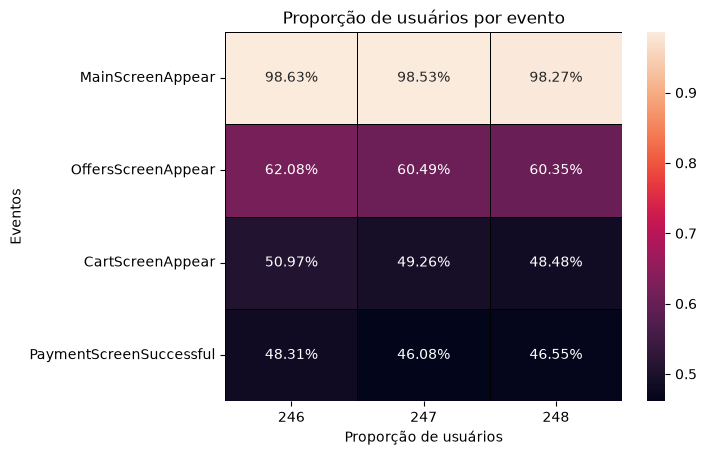

In [104]:
# Gera uma tabela pivot mostrando a quandidade de usuários de cada evento por grupo
pivot_funnel = df_logs_clean.pivot_table(
    index='event_name',
    columns='exp_id',
    values='device_id_hash',
    aggfunc='nunique'
)

# Alinha a ordem dos eventos e calcula a proporção de cada grupo
event_order = ['MainScreenAppear', 'OffersScreenAppear', 'CartScreenAppear', 'PaymentScreenSuccessful']
pivot_funnel = pivot_funnel.reindex(event_order)
pivot_funnel_pct = (pivot_funnel / users_per_group)

# Gera um mapa de calor
sns.heatmap(
    data=pivot_funnel_pct,
    annot=True,
    fmt=".2%",
    linecolor='black',
    linewidths=0.5,
)
plt.title('Proporção de usuários por evento')
plt.ylabel('Eventos')
plt.xlabel('Proporção de usuários')
plt.show()

O mapa de calor no mostra com clareza a proporção de usuários que passaram por cada etapa.\
As diferenças de cada grupo são mínimas, porém o primeiro grupo (246) apresenta valores levemente maiores.

# Teste de hipóteses
- Hipótese Nula (H0): Não existe diferença estatisticamente significativa nas taxas de conversão entre os grupos comparados (seja entre os controles 246 e 247 no teste A/A, ou entre os controles e o grupo experimental 248 nos testes A/B).

- Hipótese Alternativa (H1): Existe uma diferença estatisticamente significativa nas taxas de conversão entre os grupos comparados, indicando que a alteração da fonte (grupo 248) teve um impacto real — seja positivo ou negativo — no comportamento dos utilizadores ao longo do funil.


In [105]:
# Separa eventos por grupo e quantidade de usuários únicos
events_by_group = df_logs_clean.groupby(['exp_id','event_name']).agg(
    unique_count=('device_id_hash','nunique')
    ).reset_index().sort_values(
        by=['exp_id','unique_count'], ascending=False)
events_by_group = events_by_group[events_by_group['event_name'] != 'Tutorial']

In [106]:
# Cria a funçao para o cálculo do teste Z
def check_hypothesis(group1, group2, event_name, alpha=0.05, verbose=True):
    # Usuários únicos no evento de cada grupo
    k1 = events_by_group[(events_by_group['exp_id'] == group1) & (events_by_group['event_name'] == event_name)]['unique_count'].values[0]
    k2 = events_by_group[(events_by_group['exp_id'] == group2) & (events_by_group['event_name'] == event_name)]['unique_count'].values[0]

    # Total de usuários de cada grupo
    N1 = users_per_group[group1]
    N2 = users_per_group[group2]

    # Cálcula as porporções individuais
    p1 = k1 / N1
    p2 = k2 / N2

    # Realiza os calculos para Z-Score
    prop_combined = (k1 + k2) / (N1 + N2) # Proporções combinadas
    variance = prop_combined * (1 - prop_combined) * (1/N1 + 1/N2) # Varianacia
    se = np.sqrt(variance) # Erro padrão
    z_score = (p1 - p2) / se # Z-Score
    p_value = (1 - st.norm.cdf(abs(z_score))) * 2 # P-value

    if verbose:
        print(f"Evento: {event_name} | Grupos: {group1} vs {group2}")
        print(f"O grupo {group1} têm {k1} usuários | O grupo {group2} têm {k2} usuários")
        print(f"A proporção do {group1} é {p1:.2%} | A proporção do {group2} é {p2:.2%} ")
        print(f"p-value: {p_value:.5f}")

    
        if p_value < alpha:
            print('Rejeitamos a hipóstese nula, há diferença estatisticamente significativa')
        else:
            print('Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa')
        print()
    return p_value

# Teste entre os grupos 246 e 247

In [107]:
# Testa a hipótese para os grupos A/A
funnel_events = ['MainScreenAppear', 'OffersScreenAppear', 'CartScreenAppear', 'PaymentScreenSuccessful']

for event in funnel_events:
    check_hypothesis(246, 247, event)

Evento: MainScreenAppear | Grupos: 246 vs 247
O grupo 246 têm 2450 usuários | O grupo 247 têm 2476 usuários
A proporção do 246 é 98.63% | A proporção do 247 é 98.53% 
p-value: 0.75706
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: OffersScreenAppear | Grupos: 246 vs 247
O grupo 246 têm 1542 usuários | O grupo 247 têm 1520 usuários
A proporção do 246 é 62.08% | A proporção do 247 é 60.49% 
p-value: 0.24810
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: CartScreenAppear | Grupos: 246 vs 247
O grupo 246 têm 1266 usuários | O grupo 247 têm 1238 usuários
A proporção do 246 é 50.97% | A proporção do 247 é 49.26% 
p-value: 0.22883
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: PaymentScreenSuccessful | Grupos: 246 vs 247
O grupo 246 têm 1200 usuários | O grupo 247 têm 1158 usuários
A proporção do 246 é 48.31% | A proporção do 247 é 46.08% 
p-value: 0.11457
Não rejeitam

A função criada valida a hipótese para cada evento, entre os grupos A/A.\
É visivel que se deve rejeitar nenhuma hipótese nula, ou seja, não há diferença estatistica entre os eventos.\
Aqui podemos concluir que o evento mais popular entre eles é o 'MainScreenAppear', com 98% de presença dos usuários e um p-value de 0.757.\
Após esses testes, podemos concluir que o grupos foram dividos de forma igual.

# Teste entre os grupos 246 e 248

In [108]:
# Testa a hipótese para os grupos 246 e 248
for event in funnel_events:
    check_hypothesis(246, 248, event)

Evento: MainScreenAppear | Grupos: 246 vs 248
O grupo 246 têm 2450 usuários | O grupo 248 têm 2493 usuários
A proporção do 246 é 98.63% | A proporção do 248 é 98.27% 
p-value: 0.29497
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: OffersScreenAppear | Grupos: 246 vs 248
O grupo 246 têm 1542 usuários | O grupo 248 têm 1531 usuários
A proporção do 246 é 62.08% | A proporção do 248 é 60.35% 
p-value: 0.20836
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: CartScreenAppear | Grupos: 246 vs 248
O grupo 246 têm 1266 usuários | O grupo 248 têm 1230 usuários
A proporção do 246 é 50.97% | A proporção do 248 é 48.48% 
p-value: 0.07843
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: PaymentScreenSuccessful | Grupos: 246 vs 248
O grupo 246 têm 1200 usuários | O grupo 248 têm 1181 usuários
A proporção do 246 é 48.31% | A proporção do 248 é 46.55% 
p-value: 0.21226
Não rejeitam

Os testes não apontam diferença estatística entre os grupos 246 (controle) e 248 (teste).\
Dos 4 eventos testados, 3 temos um p-value maior que 0.20, e em todos as porporções são ligeiramente iguais, com diferença de até 2,5pp para o grupo de teste.

# Teste entre os grupos 247 e 248

In [109]:
# Testa a hipótese para os grupos 247 e 248
for event in funnel_events:
    check_hypothesis(247, 248, event)

Evento: MainScreenAppear | Grupos: 247 vs 248
O grupo 247 têm 2476 usuários | O grupo 248 têm 2493 usuários
A proporção do 247 é 98.53% | A proporção do 248 é 98.27% 
p-value: 0.45871
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: OffersScreenAppear | Grupos: 247 vs 248
O grupo 247 têm 1520 usuários | O grupo 248 têm 1531 usuários
A proporção do 247 é 60.49% | A proporção do 248 é 60.35% 
p-value: 0.91978
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: CartScreenAppear | Grupos: 247 vs 248
O grupo 247 têm 1238 usuários | O grupo 248 têm 1230 usuários
A proporção do 247 é 49.26% | A proporção do 248 é 48.48% 
p-value: 0.57862
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: PaymentScreenSuccessful | Grupos: 247 vs 248
O grupo 247 têm 1158 usuários | O grupo 248 têm 1181 usuários
A proporção do 247 é 46.08% | A proporção do 248 é 46.55% 
p-value: 0.73734
Não rejeitam

Com um p-value considerávelmente maior que os grupos 246 e 248, os grupos 247 e 248 também nao possuem diferença estatística.\
Todos os testes apontaram um p-value maior que 0.40 chegando até 0,90, as propoções não chegam a 1pp de diferença entre os eventos.

In [110]:
# Combina os grupos 246 e 247 para comparar com o grupo 248
df_combined = events_by_group[events_by_group['exp_id'].isin([246, 247])].groupby('event_name', as_index=False)['unique_count'].sum()
df_combined['exp_id'] = '246_247'
events_by_group = pd.concat([events_by_group, df_combined], ignore_index=True)
users_per_group['246_247'] = users_per_group[246] + users_per_group[247]

In [111]:
# Testa a hipótese para os grupos 246_247 e 248
for event in funnel_events:
    check_hypothesis('246_247', 248, event)

Evento: MainScreenAppear | Grupos: 246_247 vs 248
O grupo 246_247 têm 4926 usuários | O grupo 248 têm 2493 usuários
A proporção do 246_247 é 98.58% | A proporção do 248 é 98.27% 
p-value: 0.29425
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: OffersScreenAppear | Grupos: 246_247 vs 248
O grupo 246_247 têm 3062 usuários | O grupo 248 têm 1531 usuários
A proporção do 246_247 é 61.28% | A proporção do 248 é 60.35% 
p-value: 0.43426
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: CartScreenAppear | Grupos: 246_247 vs 248
O grupo 246_247 têm 2504 usuários | O grupo 248 têm 1230 usuários
A proporção do 246_247 é 50.11% | A proporção do 248 é 48.48% 
p-value: 0.18176
Não rejeitamos a hipótese nula, não há diferença estatisticamente significativa

Evento: PaymentScreenSuccessful | Grupos: 246_247 vs 248
O grupo 246_247 têm 2358 usuários | O grupo 248 têm 1181 usuários
A proporção do 246_247 é 47.19% | A proporçã

Mesmo com uma amostra do grupo de controle duas vezes maior, ainda não temos diferença estatistica significativa.\
Ambos um grupos tiveram p-values acima de 0.18, até 0.60, e a diferença da proporção chega a 1,6pp no terceiro evento.

Realizamos no total 16 testes, dividindo 4 por comparação (4 no teste A/A, 4 no A/B 246x248, 4 no A/B 247x248 e 4 no A/A Combinadox248).\
Ao adotar alpha = 0.05 para cada teste individualmente, a probabilidade acumulada de observar ao menos um falso positivo (Erro Tipo I) ao longo das 16 verificações aumenta consideravelmente.\
Por isso, é fundamental testar correções de significância como a Correção de Bonferroni para garantir que nenhuma das decisões foi tomada sob um risco inflacionado de erro. 

# Aplicação da correção de bonferroni

In [112]:
# Função para mostrar os p-values com o ajuste de Bonferroni
def show_pvalues_with_bonferroni():
    comparisons = [
        (246,247),
        (246,248),
        (247,248),
        ('246_247',248),
    ]

    # Ajuste de Bonferroni
    inital_alpha = 0.05
    n_tests_by_groups = len(comparisons)
    adjusted_alpha = inital_alpha / n_tests_by_groups

    # Exibe os p-values e se rejeita ou não a hipótese nula com o ajuste de Bonferroni
    print(f'Limiar ajustado para: {adjusted_alpha}')
    for group1, group2 in comparisons:
        for event in funnel_events:
            p_val = check_hypothesis(group1, group2, event, verbose=False)
            print(f"Grupos {group1} vs {group2} | p-value: {p_val:.5f} | {"Rejeita H0" if p_val < adjusted_alpha else "Não rejeita H0"}")

In [113]:
show_pvalues_with_bonferroni() # Executa a função para mostrar os p-values com o ajuste

Limiar ajustado para: 0.0125
Grupos 246 vs 247 | p-value: 0.75706 | Não rejeita H0
Grupos 246 vs 247 | p-value: 0.24810 | Não rejeita H0
Grupos 246 vs 247 | p-value: 0.22883 | Não rejeita H0
Grupos 246 vs 247 | p-value: 0.11457 | Não rejeita H0
Grupos 246 vs 248 | p-value: 0.29497 | Não rejeita H0
Grupos 246 vs 248 | p-value: 0.20836 | Não rejeita H0
Grupos 246 vs 248 | p-value: 0.07843 | Não rejeita H0
Grupos 246 vs 248 | p-value: 0.21226 | Não rejeita H0
Grupos 247 vs 248 | p-value: 0.45871 | Não rejeita H0
Grupos 247 vs 248 | p-value: 0.91978 | Não rejeita H0
Grupos 247 vs 248 | p-value: 0.57862 | Não rejeita H0
Grupos 247 vs 248 | p-value: 0.73734 | Não rejeita H0
Grupos 246_247 vs 248 | p-value: 0.29425 | Não rejeita H0
Grupos 246_247 vs 248 | p-value: 0.43426 | Não rejeita H0
Grupos 246_247 vs 248 | p-value: 0.18176 | Não rejeita H0
Grupos 246_247 vs 248 | p-value: 0.60043 | Não rejeita H0


Devido ao risco de inflação do Erro Tipo I (falsos positivos) ao realizar múltiplos testes em simultâneo (16 testes no total), aplicamos a Correção de Bonferroni.\
Dividindo o limiar pelo numero de eventos (0.05 / 4 = 0.0125), obtemos a correção, e de acordo com os teste realizados, nenhum p-value chegou a ultrapassar o limiar definido.\
Por fim, mantemos a hipótese nula em todos os casos.

# Conclusão Geral do Experimento
- (Teste A/A/B)Validação (Teste A/A): A comparação entre os grupos de controle 246 e 247 confirmou que a divisão da amostra foi feita de forma homogénea, sem diferenças estatisticamente significativas entre eles.
- Testes de Hipótese (Testes A/B): Nenhuma das comparações do grupo experimental 248 (contra o grupo 246, contra o 247, ou contra o controle combinado 246+247) apresentou diferenças estatisticamente relevantes nos eventos do funil.
- Correção de Bonferroni: Ao aplicar o ajuste rigoroso para múltiplos testes (alpha = 0.0125), manteve-se a constatação de que nenhum p-valor atingiu o limiar de significância.
- Declaração final: A alteração de fontes na interface não impactou o comportamento de conversão dos utilizadores (nem positiva, nem negativamente).